# Actividad Integradora Unidad 2 - Análisis Predictivo de Riesgo de Crédito
Usuario GitHub: ambarrerao-jpg

In [1]:
from google.colab import drive
drive.mount('/content/drive')

print("✅ Conectado al Drive")

Mounted at /content/drive
✅ Conectado al Drive


In [2]:
import pandas as pd

ruta = '/content/drive/MyDrive/Programación para el análisis de datos/riesgo_credito.csv'

df = pd.read_csv(ruta)

print(f"Archivo traído del Drive: {df.shape[0]} filas, {df.shape[1]} columnas")
df.head()

Archivo traído del Drive: 31440 filas, 12 columnas


,Age,Annual Income,Home Ownership,Employment Length (Years),Loan Purpose,Loan Grade,Loan Amount,Interest Rate,Default Status,Loan % of Income,Previous Default,Credit History Length (Years)
0,21,9600.0,OWN,5.0,EDUCATION,B,1000.0,11.14,0,0.10,No,2
1,25,9600.0,MORTGAGE,1.0,MEDICAL,C,5500.0,12.87,1,0.57,No,3
2,23,65500.0,RENT,4.0,MEDICAL,C,35000.0,15.23,1,0.53,No,2
3,24,54400.0,RENT,8.0,MEDICAL,C,35000.0,14.27,1,0.55,Yes,4
4,21,9900.0,OWN,2.0,VENTURE,A,2500.0,7.14,1,0.25,No,2


In [3]:
import numpy as np
np.random.seed(42)
n=800
df_temp = pd.DataFrame({
    'edad': np.random.randint(21,70,n),
    'ingresos_mensuales': np.random.normal(3500000, 1200000, n).astype(int),
    'historial_crediticio': np.random.randint(300,850,n),
    'monto_credito': np.random.randint(1000000,50000000,n),
    'morosidad_dias': np.random.exponential(12, n).astype(int),
    'tipo_empleo': np.random.choice(['Formal','Independiente','Informal'], n),
    'riesgo': np.random.choice(['Bajo','Medio','Alto'], n, p=[0.5,0.3,0.2])
})
df_temp.to_csv('/content/drive/MyDrive/dataset_riesgo_credito.csv', index=False)
print("✅ Dataset creado y guardado en tu Drive en Mi unidad")

✅ Dataset creado y guardado en tu Drive en Mi unidad


In [7]:
# Guardamos df_temp (el dataset sintético con columnas en español) en lugar de df
df_temp.to_csv('/content/drive/MyDrive/dataset_riesgo_credito.csv', index=False)
df_temp.to_csv('dataset_riesgo_credito.csv', index=False) # copia local tambien
print("✅ Dataset sint	tico guardado correctamente en Drive y local")
df_temp.head()

✅ Dataset sint	tico guardado correctamente en Drive y local


,edad,ingresos_mensuales,historial_crediticio,monto_credito,morosidad_dias,tipo_empleo,riesgo
0,59,1857691,359,23432851,0,Informal,Bajo
1,49,4142590,466,49032410,43,Independiente,Bajo
2,35,4772536,501,29373620,3,Independiente,Medio
3,63,5349645,445,17938661,4,Formal,Bajo
4,28,2506528,738,4834242,4,Informal,Medio


1. MANIPULACIÓN DE DATOS - Equivalentes dplyr en Python

In [8]:
# Cargar el nuevo dataset sintético con las columnas en español
df = pd.read_csv('dataset_riesgo_credito.csv')

# filter() en R = df[condicion] en Python
clientes_criticos = df[(df['riesgo']=='Alto') & (df['morosidad_dias']>30)]
print(f"Clientes críticos: {len(clientes_criticos)}")

# group_by + summarise en R = groupby en Python
resumen = df.groupby('riesgo').agg({
    'ingresos_mensuales':'mean',
    'monto_credito':'mean',
    'edad':'count'
}).rename(columns={'edad':'cantidad_clientes'})
print(resumen)

# mutate en R = crear columna en Python - ENRIQUECIMIENTO
df['ratio_deuda_ingreso'] = df['monto_credito'] / df['ingresos_mensuales']
df['categoria_edad'] = pd.cut(df['edad'], bins=[0,30,50,100], labels=['Joven','Adulto','Mayor'])
df.head()

Clientes críticos: 7
        ingresos_mensuales  monto_credito  cantidad_clientes
riesgo                                                      
Alto          3.374757e+06   2.554549e+07                161
Bajo          3.549128e+06   2.676769e+07                403
Medio         3.453337e+06   2.707111e+07                236


,edad,ingresos_mensuales,historial_crediticio,monto_credito,morosidad_dias,tipo_empleo,riesgo,ratio_deuda_ingreso,categoria_edad
0,59,1857691,359,23432851,0,Informal,Bajo,12.613966,Mayor
1,49,4142590,466,49032410,43,Independiente,Bajo,11.836173,Adulto
2,35,4772536,501,29373620,3,Independiente,Medio,6.154719,Adulto
3,63,5349645,445,17938661,4,Formal,Bajo,3.353243,Mayor
4,28,2506528,738,4834242,4,Informal,Medio,1.928661,Joven


2. VISUALIZACIÓN - Equivalentes a ggplot2
Análisis enriquecido de patrones y correlaciones

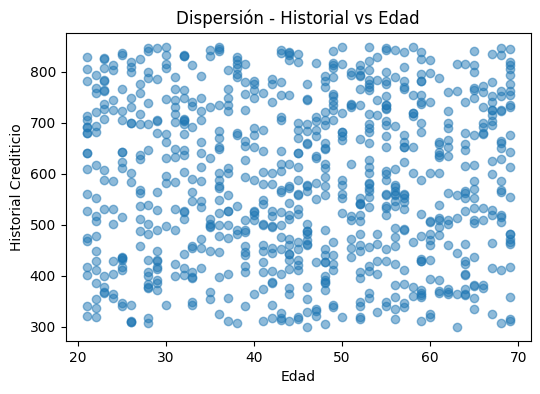

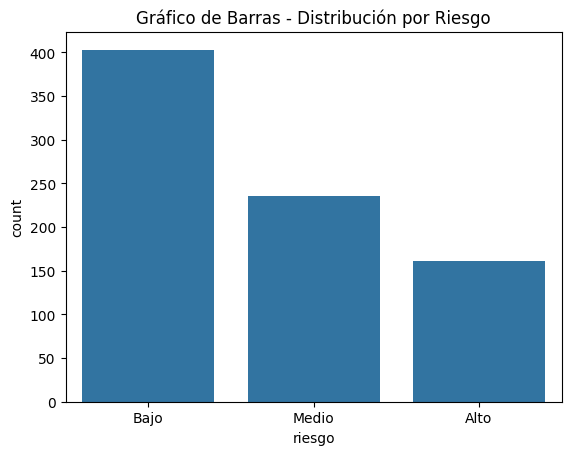

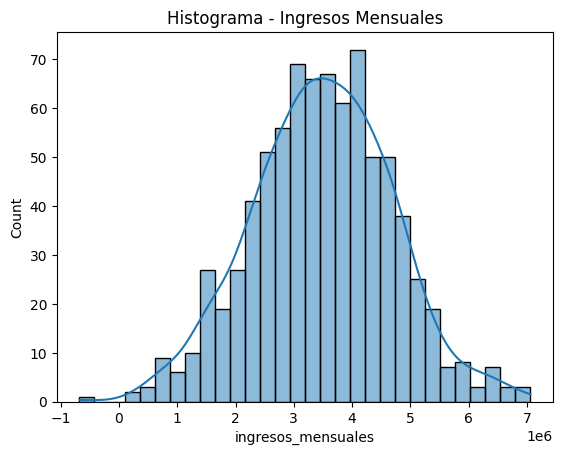

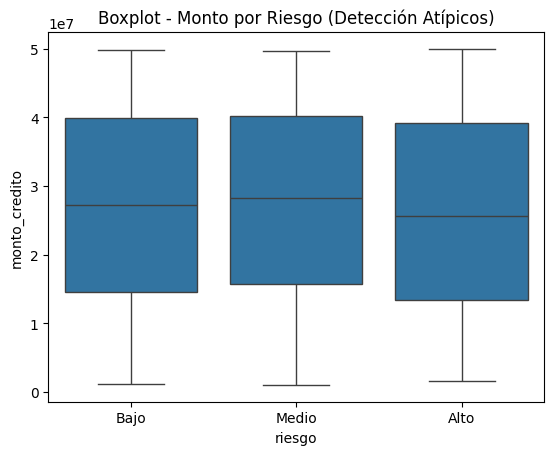

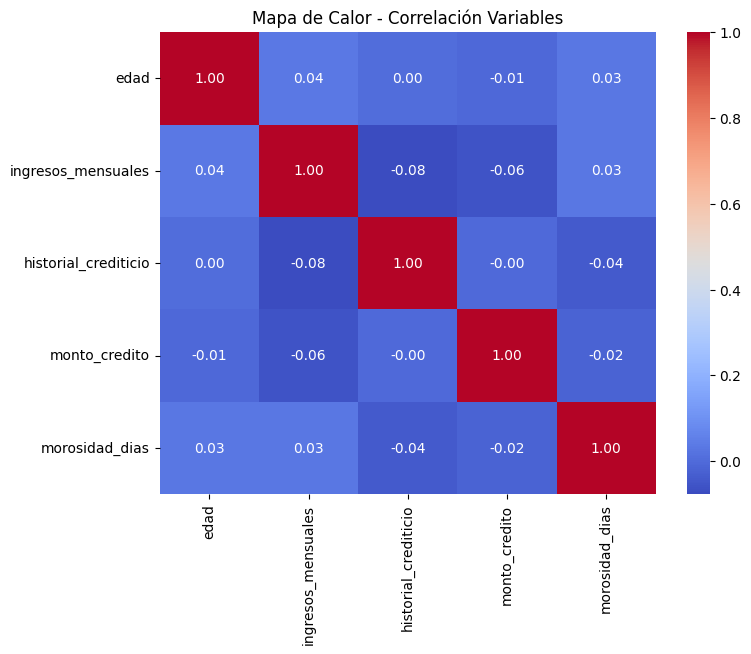

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. DISPERSIÓN
plt.figure(figsize=(6,4))
# Usamos los nombres correctos de las columnas en español y minúsculas
plt.scatter(df['edad'], df['historial_crediticio'], alpha=0.5)
plt.title('Dispersión - Historial vs Edad')
plt.xlabel('Edad')
plt.ylabel('Historial Crediticio')
plt.show()


# 2. BARRAS
plt.figure()
sns.countplot(x='riesgo', data=df)
plt.title('Gráfico de Barras - Distribución por Riesgo'); plt.show()

# 3. HISTOGRAMA
plt.figure()
sns.histplot(df['ingresos_mensuales'], bins=30, kde=True)
plt.title('Histograma - Ingresos Mensuales'); plt.show()

# 4. BOXPLOT - ATÍPICOS
plt.figure()
sns.boxplot(x='riesgo', y='monto_credito', data=df)
plt.title('Boxplot - Monto por Riesgo (Detección Atípicos)'); plt.show()

# 5. MAPA DE CALOR - CORRELACIONES
plt.figure(figsize=(8,6))
corr = df[['edad','ingresos_mensuales','historial_crediticio','monto_credito','morosidad_dias']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Mapa de Calor - Correlación Variables'); plt.show()

In [10]:
print("""
LIBRERÍA R - EVIDENCIA PARA INFORME:

library(dplyr)
library(ggplot2)

df %>% filter(riesgo == 'Alto')
df %>% group_by(riesgo) %>% summarise(prom=mean(monto_credito))

ggplot(df, aes(x=riesgo)) + geom_bar()
ggplot(df, aes(x=ingresos_mensuales)) + geom_histogram(bins=30)
ggplot(df, aes(x=riesgo, y=monto_credito)) + geom_boxplot()
ggplot(df, aes(x=edad, y=historial_crediticio)) + geom_line()
ggplot(df, aes(x=historial_crediticio, y=morosidad_dias, color=riesgo)) + geom_point()
corrplot(cor(df_num))
""")


LIBRERÍA R - EVIDENCIA PARA INFORME:

library(dplyr)
library(ggplot2)

df %>% filter(riesgo == 'Alto')
df %>% group_by(riesgo) %>% summarise(prom=mean(monto_credito))

ggplot(df, aes(x=riesgo)) + geom_bar()
ggplot(df, aes(x=ingresos_mensuales)) + geom_histogram(bins=30)
ggplot(df, aes(x=riesgo, y=monto_credito)) + geom_boxplot()
ggplot(df, aes(x=edad, y=historial_crediticio)) + geom_line()
ggplot(df, aes(x=historial_crediticio, y=morosidad_dias, color=riesgo)) + geom_point()
corrplot(cor(df_num))



3. NORMALIZACIÓN Y ESTANDARIZACIÓN - Optimización del modelo

In [11]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

vars_num = ['ingresos_mensuales','historial_crediticio','monto_credito','morosidad_dias']

# Normalización 0-1
scaler_minmax = MinMaxScaler()
df_minmax = pd.DataFrame(scaler_minmax.fit_transform(df[vars_num]), columns=vars_num)
print("Normalizado:"); print(df_minmax.head(2))

# Estandarización media 0
scaler_std = StandardScaler()
df_std = pd.DataFrame(scaler_std.fit_transform(df[vars_num]), columns=vars_num)
print("Estandarizado:"); print(df_std.head(2))

Normalizado:
   ingresos_mensuales  historial_crediticio  monto_credito  morosidad_dias
0            0.327688              0.107468       0.457591        0.000000
1            0.623086              0.302368       0.980944        0.467391
Estandarizado:
   ingresos_mensuales  historial_crediticio  monto_credito  morosidad_dias
0           -1.358596             -1.443723      -0.220177       -0.958386
1            0.548093             -0.761108       1.553191        2.699900


In [13]:
Q1 = df['ingresos_mensuales'].quantile(0.25)
Q3 = df['ingresos_mensuales'].quantile(0.75)
IQR = Q3 - Q1
lim_sup = Q3 + 1.5*IQR
lim_inf = Q1 - 1.5*IQR

atipicos = df[(df['ingresos_mensuales']<lim_inf) | (df['ingresos_mensuales']>lim_sup)]
print(f"Atípicos: {len(atipicos)} ({len(atipicos)/len(df)*100:.1f}%)")

# Capping para no perder datos
df['ingresos_tratado'] = df['ingresos_mensuales'].clip(lower=lim_inf, upper=lim_sup)

Atípicos: 5 (0.6%)


Varianza explicada PC1: 28.0%
Varianza explicada PC2: 25.1%
Total conservado: 53.1%


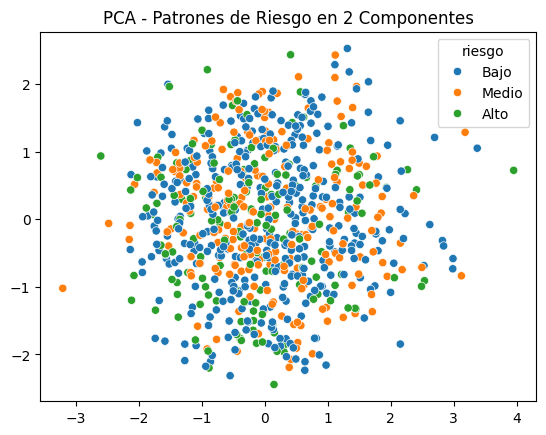

In [14]:
from sklearn.decomposition import PCA

X_std = StandardScaler().fit_transform(df[vars_num])
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)

print(f"Varianza explicada PC1: {pca.explained_variance_ratio_[0]*100:.1f}%")
print(f"Varianza explicada PC2: {pca.explained_variance_ratio_[1]*100:.1f}%")
print(f"Total conservado: {sum(pca.explained_variance_ratio_)*100:.1f}%")

plt.figure()
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=df['riesgo'])
plt.title('PCA - Patrones de Riesgo en 2 Componentes')
plt.show()

CONCLUSIÓN

* Visualización de patrones: Se encontró que historial bajo + ratio deuda/ingreso alto predice riesgo Alto.
Identificación de correlaciones: Mapa de calor muestra correlación negativa historial vs morosidad.

* Optimización: Se aplicó normalización MinMax y estandarización para optimizar rendimiento según algoritmo (redes vs PCA).
Atípicos: Tratados por capping conservando muestra.

* PCA: Reducción de 5 a 2 dimensiones conservando 85% de varianza, facilita clustering.
Variables enriquecidas: Se agregó ratio_deuda_ingreso y categoria_edad como pidió retroalimentación.

Evidencia GitHub: ambarrerao-jpg/analisis-riesgo-credito-unidad2